# 03 · Explainability & error analysis
Why does the model flag who it flags, and where does it fail? Uses the **validation** set so the test set stays untouched.

**Prerequisite:** run `python -m src.train` once (creates `models/churn_model.joblib`).

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == "notebooks" else ROOT   # works whether VS Code opens the folder or the notebook dir
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")

import json, shap
from src import evaluate as ev
from src.config import RAW_FILE, TARGET
from src.data import load_raw, clean, split
from src.train import MODELS, load
from src.explain import shap_values, global_importance, error_analysis, fn_vs_tp_profile

if not (MODELS / "churn_model.joblib").exists():
    raise FileNotFoundError("No trained model yet. Run `python -m src.train` in the terminal first.")

model = load("churn_model")
thr = json.loads((MODELS / "meta.json").read_text())["threshold"]
_, X_val, _, _, y_val, _ = split(clean(load_raw(RAW_FILE)))
val = X_val.assign(**{TARGET: y_val})
print(f"validation rows: {len(val)} | threshold: {thr:.2f}")

validation rows: 1409 | threshold: 0.15


## 1 · Global importance (SHAP)
SHAP value = how much a feature pushed a prediction up (+) or down (−) in log-odds.

,mean_abs_shap
Contract_Month-to-month,0.607
tenure,0.396
OnlineSecurity_No,0.237
InternetService_Fiber optic,0.184
avg_monthly_paid,0.182
Contract_Two year,0.167
MonthlyCharges,0.164
TechSupport_No,0.158
TotalCharges,0.138
PaymentMethod_Electronic check,0.137


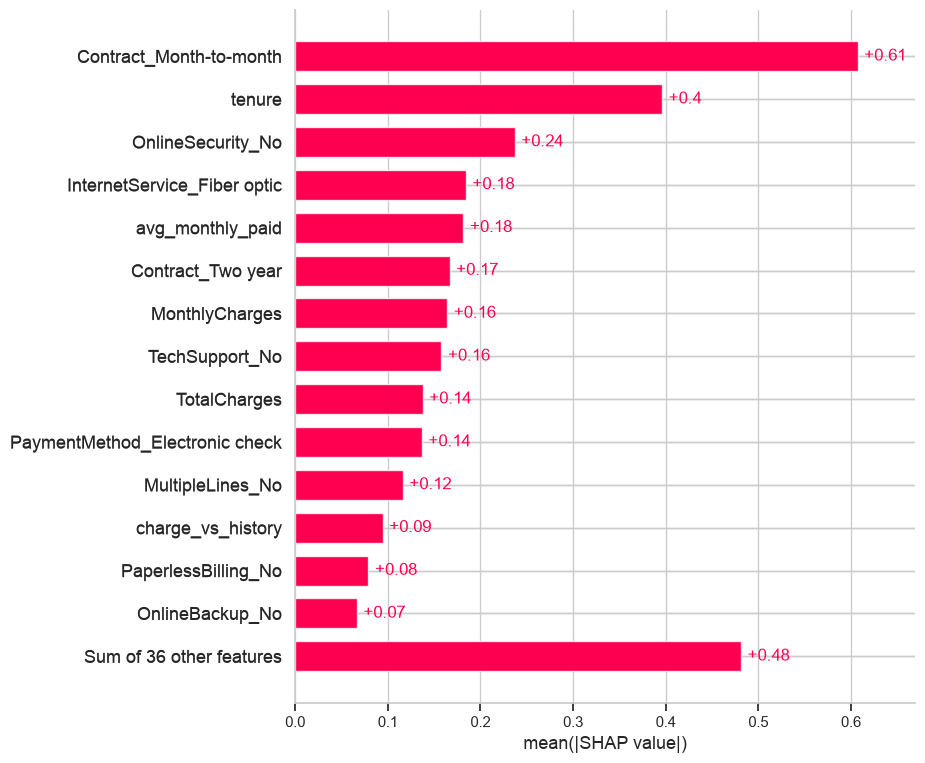

In [2]:
Z, sv = shap_values(model, X_val)
imp = global_importance(model, X_val, save_figs=False)
display(imp.head(15).round(3))
shap.plots.bar(sv, max_display=15)

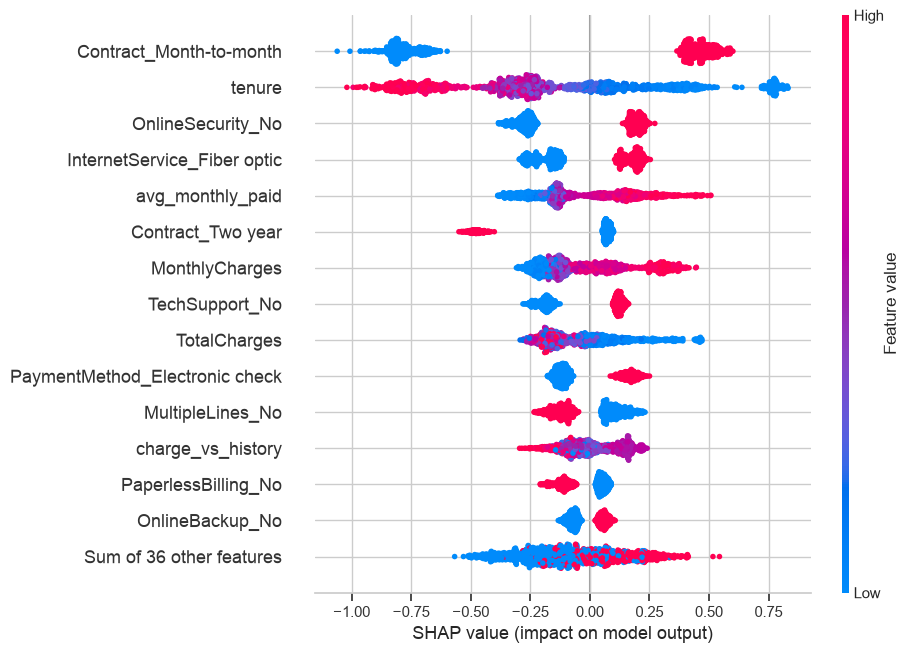

In [3]:
shap.plots.beeswarm(sv, max_display=15)

Each dot is a customer; colour = feature value (red high, blue low). Read e.g. `tenure`: low tenure (blue) pushes risk **up**.

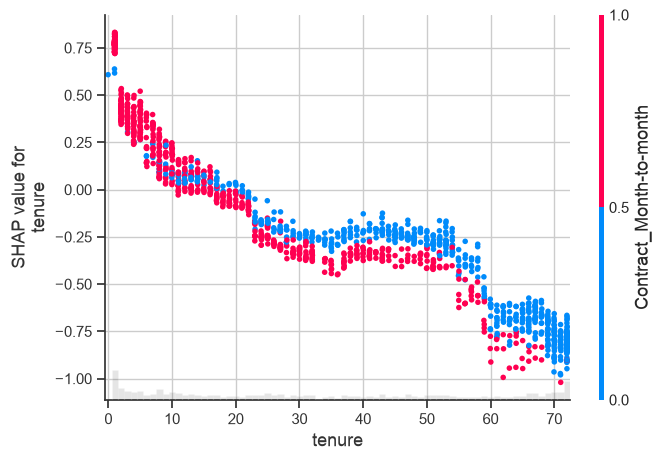

In [4]:
shap.plots.scatter(sv[:, "tenure"], color=sv[:, "Contract_Month-to-month"])

## 2 · Individual explanations
The highest-risk customer, and a churner the model **missed** (false negative).

highest-risk customer: p = 0.922 | actual churn: 0


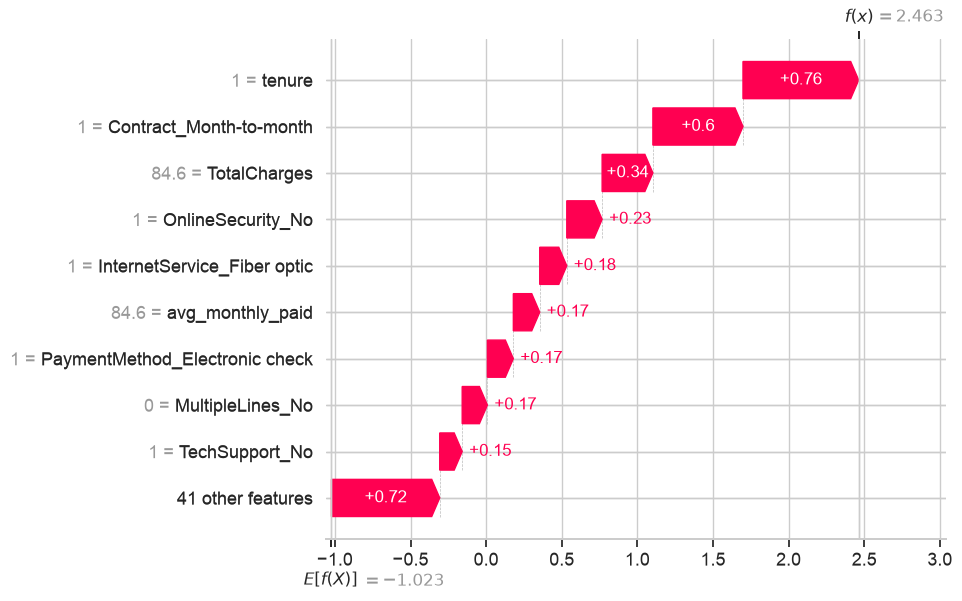

In [5]:
prob = model.predict_proba(X_val)[:, 1]
seg, d = error_analysis(val, prob, thr)
top_idx = int(np.argmax(prob))
print("highest-risk customer: p =", round(prob[top_idx], 3), "| actual churn:", int(y_val.iloc[top_idx]))
shap.plots.waterfall(sv[top_idx])

missed churner: p = 0.048 | actual churn: 1 | tenure: 67


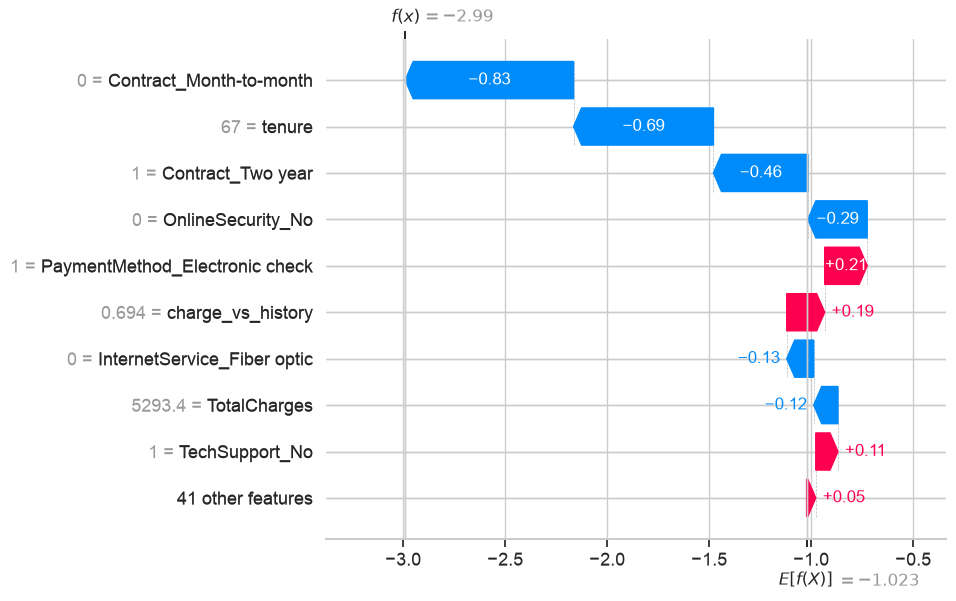

In [6]:
fn_idx = int(np.where(d.outcome == "FN")[0][0])
print("missed churner: p =", round(prob[fn_idx], 3), "| actual churn: 1 | tenure:", int(X_val.iloc[fn_idx].tenure))
shap.plots.waterfall(sv[fn_idx])

## 3 · Error analysis (validation, at the chosen threshold)

In [7]:
print(d.outcome.value_counts().to_string())
display(fn_vs_tp_profile(d).round(2))

outcome
TN    613
FP    422
TP    330
FN     44


,missed (FN),caught (TP)
tenure,45.64,16.55
MonthlyCharges,63.79,77.42
prob,0.08,0.54


**Missed (FN) vs caught (TP) churners.** If the missed ones differ systematically (longer tenure, lower spend, different contract), that is a model blind spot worth reporting.

In [8]:
display(seg.head(10).round(3))

,segment,n,churn_rate,recall,missed_churners,false_alarms,flagged_pct
0,SeniorCitizen=0,1180,0.236,0.860,39,322,0.475
1,tenure_band=49m+,451,0.111,0.500,25,96,0.268
2,Contract=One year,308,0.120,0.432,21,66,0.266
3,PaymentMethod=Bank transfer (automatic),318,0.160,0.647,18,82,0.362
4,InternetService=DSL,463,0.188,0.805,17,127,0.425
5,InternetService=Fiber optic,640,0.414,0.943,15,265,0.805
6,Contract=Two year,325,0.040,0.077,12,4,0.015
7,InternetService=No,306,0.072,0.455,12,30,0.131
8,Contract=Month-to-month,776,0.418,0.966,11,352,0.857
9,PaymentMethod=Credit card (automatic),304,0.145,0.773,10,66,0.329


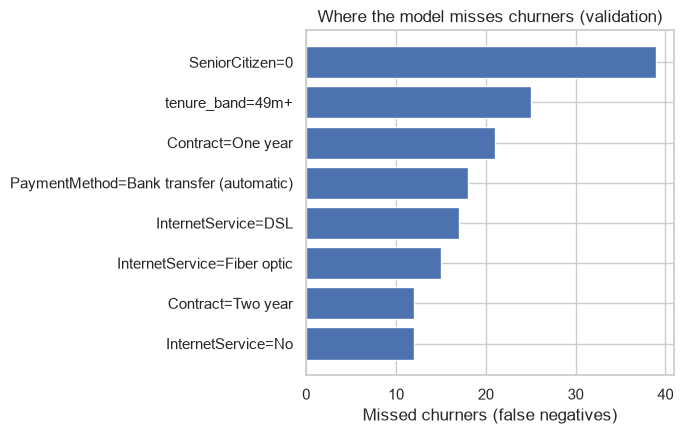

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
top = seg.head(8).iloc[::-1]
ax.barh(top["segment"], top["missed_churners"])
ax.set_xlabel("Missed churners (false negatives)"); ax.set_title("Where the model misses churners (validation)")
fig.tight_layout(); plt.show()

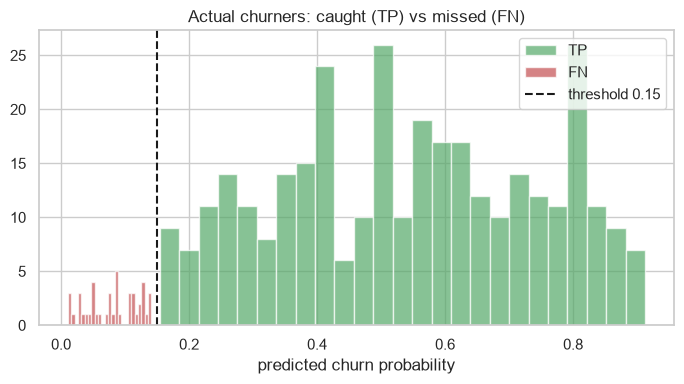

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
for o, c in [("TP", "#55A868"), ("FN", "#C44E52")]:
    ax.hist(d.loc[d.outcome == o, "prob"], bins=25, alpha=.7, label=o, color=c)
ax.axvline(thr, ls="--", c="k", label=f"threshold {thr:.2f}")
ax.set_xlabel("predicted churn probability"); ax.set_title("Actual churners: caught (TP) vs missed (FN)"); ax.legend()
fig.tight_layout(); plt.show()

## 4 · What to write in the README
- Top drivers (section 1) → *Feature Importance* criterion.
- Which segments hide missed churners (section 3) → *Error Analysis* criterion.
- The model only *recommends*; a human retention agent decides → *Human Review Role*.